In [ ]:
import pandas as pd
import numpy as np

In [2]:
from glaciation_time_estimator.auxiliary_func.chunking_data import ChunkLoader

In [84]:
cloud_df = pd.read_parquet("/Volumes/University_stuff/Parquet_dataset/2008_all.parquet")

In [85]:
glac_df = pd.read_parquet("/Volumes/University_stuff/Parquet_dataset/2008_glac_04.parquet")

In [95]:
def extract_relative_ice_fraction(
    df,
    hist_col="ice_frac_hist",
    peak_col="Glac_peak_ind",
    rel_range=(-8, 9),
    eps=1e-4,
    demean_within_cloud=False,
):
    rel_inds = np.arange(rel_range[0], rel_range[1])

    rows = []
    cloud_ids = []

    for idx, row in tqdm(df.iterrows(), total=len(df), desc="Extracting relative IF"):
        hist = row[hist_col]
        peak_ind = row[peak_col]

        if hist is None or pd.isna(peak_ind):
            continue

        x = np.asarray(hist, dtype=float)
        peak_ind = int(peak_ind)

        valid = (
            np.isfinite(x)
            & (x >= 0 - eps)
            & (x <= 1 + eps)
        )

        x = x.copy()
        x[~valid] = np.nan

        if np.isfinite(x).sum() < 4:
            continue

        if demean_within_cloud:
            x = x - np.nanmean(x)

        vals = []

        for rel_ind in rel_inds:
            abs_ind = peak_ind + rel_ind

            if abs_ind < 0 or abs_ind >= len(x):
                vals.append(np.nan)
            else:
                vals.append(x[abs_ind])

        rows.append(vals)
        cloud_ids.append(idx)

    return pd.DataFrame(rows, index=cloud_ids, columns=rel_inds)

In [92]:
def correlation_with_peak(rel_df, peak_rel_ind=0, min_samples=30):
    """
    Correlate every relative-time column with the peak column.
    """
    peak = rel_df[peak_rel_ind]

    results = []

    for rel_ind in rel_df.columns:
        y = rel_df[rel_ind]

        mask = np.isfinite(peak) & np.isfinite(y)

        n = mask.sum()

        if n < min_samples:
            corr = np.nan
        else:
            corr = np.corrcoef(peak[mask], y[mask])[0, 1]

        results.append({
            "rel_ind": rel_ind,
            "rel_time_min": rel_ind * 15,
            "corr_with_peak": corr,
            "n_clouds": n,
        })

    return pd.DataFrame(results)

In [99]:
import numpy as np
import pandas as pd
from tqdm.auto import tqdm


def pearson_corr_manual(x, y, min_samples=30):
    mask = np.isfinite(x) & np.isfinite(y)

    if mask.sum() < min_samples:
        return np.nan

    x = np.asarray(x[mask], dtype=float)
    y = np.asarray(y[mask], dtype=float)

    x = x - np.mean(x)
    y = y - np.mean(y)

    denom = np.sqrt(np.sum(x**2) * np.sum(y**2))

    if denom == 0:
        return np.nan

    return np.sum(x * y) / denom


def correlation_with_peak_ci(
    rel_df,
    peak_rel_ind=0,
    min_samples=30,
    n_boot=500,
    ci=(2.5, 97.5),
    random_state=0,
):
    """
    Correlation of each relative-time column with the peak column,
    with cloud-level bootstrap confidence intervals.

    rel_df rows = clouds
    rel_df columns = relative time indices
    """

    rng = np.random.default_rng(random_state)

    rel_cols = np.asarray(rel_df.columns)
    values = rel_df.to_numpy(dtype=float)

    if peak_rel_ind not in rel_df.columns:
        raise ValueError(f"peak_rel_ind={peak_rel_ind} not found in rel_df columns")

    peak_col_pos = np.where(rel_cols == peak_rel_ind)[0][0]

    n_clouds_total = values.shape[0]
    n_lags = values.shape[1]

    # Main estimate
    main_corrs = np.full(n_lags, np.nan)
    n_clouds = np.full(n_lags, 0, dtype=int)

    peak = values[:, peak_col_pos]

    for j in range(n_lags):
        y = values[:, j]
        mask = np.isfinite(peak) & np.isfinite(y)
        n_clouds[j] = mask.sum()
        main_corrs[j] = pearson_corr_manual(peak, y, min_samples=min_samples)

    # Bootstrap estimates
    boot_corrs = np.full((n_boot, n_lags), np.nan)

    for b in tqdm(range(n_boot), desc="Bootstrap correlations"):
        inds = rng.integers(0, n_clouds_total, size=n_clouds_total)

        boot_values = values[inds, :]
        boot_peak = boot_values[:, peak_col_pos]

        for j in range(n_lags):
            y = boot_values[:, j]
            boot_corrs[b, j] = pearson_corr_manual(
                boot_peak,
                y,
                min_samples=min_samples,
            )

    ci_low = np.nanpercentile(boot_corrs, ci[0], axis=0)
    ci_high = np.nanpercentile(boot_corrs, ci[1], axis=0)

    out = pd.DataFrame({
        "rel_ind": rel_cols,
        "rel_time_min": rel_cols * 15,
        "corr_with_peak": main_corrs,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "n_clouds": n_clouds,
    })

    return out

In [ ]:
rel_if_raw = extract_relative_ice_fraction(
    glac_df,
    rel_range=(-8, 9),
    demean_within_cloud=False,
)

rel_if_anom = extract_relative_ice_fraction(
    glac_df,
    rel_range=(-8, 9),
    demean_within_cloud=True,
)

corr_raw = correlation_with_peak(rel_if_raw)
corr_anom = correlation_with_peak(rel_if_anom)

Extracting relative IF: 100%|██████████| 132138/132138 [00:04<00:00, 26605.96it/s]


In [116]:
corr_peak_ci = correlation_with_peak_ci(
    rel_if_anom,
    peak_rel_ind=0,
    min_samples=100,
    n_boot=100,
    random_state=0,
)

corr_peak_ci

Bootstrap correlations: 100%|██████████| 100/100 [00:03<00:00, 25.98it/s]


,rel_ind,rel_time_min,corr_with_peak,ci_low,ci_high,n_clouds
0,-8,-120,-0.029552,-0.037145,-0.021324,54291
1,-7,-105,-0.004626,-0.014851,0.002702,62006
2,-6,-90,0.024141,0.016322,0.031953,71847
3,-5,-75,0.060242,0.053261,0.066412,84286
4,-4,-60,0.101009,0.095635,0.107038,100090
5,-3,-45,0.151428,0.146546,0.158102,121392
6,-2,-30,0.203986,0.198330,0.209977,132138
7,-1,-15,0.370893,0.365448,0.377410,132138
8,0,0,1.000000,1.000000,1.000000,132138
9,1,15,0.488670,0.480461,0.495947,81832


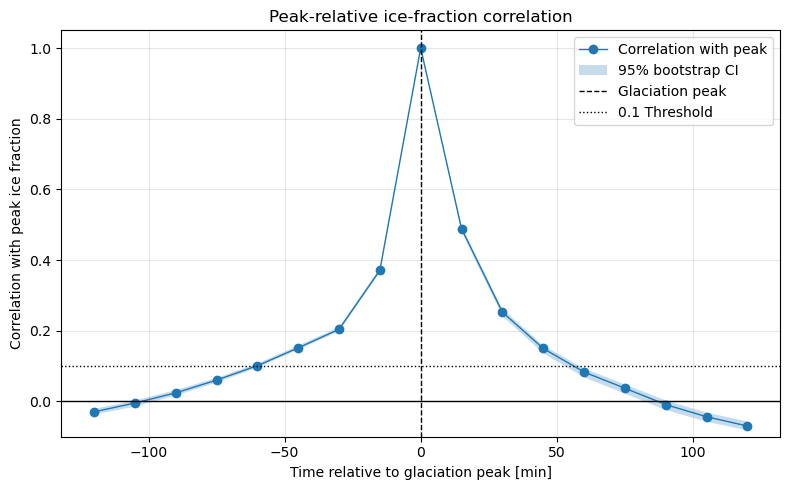

In [125]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    corr_peak_ci["rel_time_min"],
    corr_peak_ci["corr_with_peak"],
    marker="o",
    linewidth=1,
    label="Correlation with peak",
)

plt.fill_between(
    corr_peak_ci["rel_time_min"],
    corr_peak_ci["ci_low"],
    corr_peak_ci["ci_high"],
    alpha=0.25,
    label="95% bootstrap CI",
)

plt.axvline(0, color="k", linestyle="--", linewidth=1, label="Glaciation peak")
plt.axhline(0, color="k", linewidth=1)
# plt.axhline(1/np.e, color="k", linestyle="--", linewidth=1, label="1/e")
plt.axhline(0.1, color="k", linewidth=1,linestyle="dotted",label="0.1 Threshold")


plt.xlabel("Time relative to glaciation peak [min]")
plt.ylabel("Correlation with peak ice fraction")
plt.title("Peak-relative ice-fraction correlation")
plt.ylim(-0.1, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

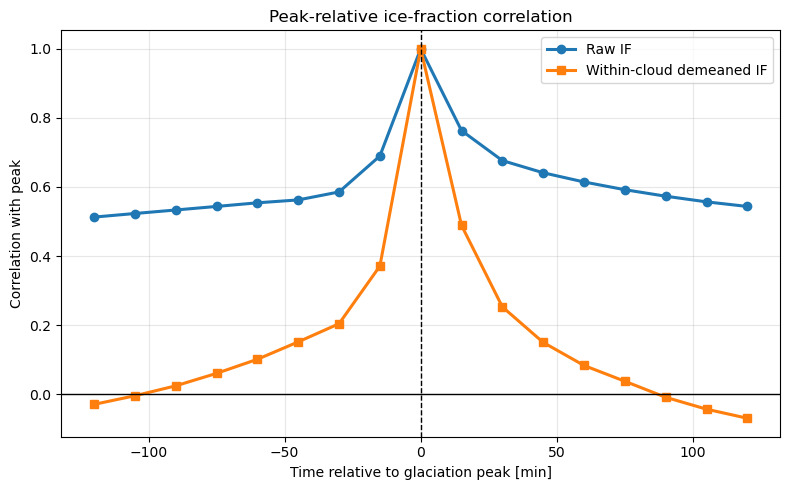

In [98]:
plt.figure(figsize=(8, 5))

plt.plot(
    corr_raw["rel_time_min"],
    corr_raw["corr_with_peak"],
    marker="o",
    linewidth=2.2,
    label="Raw IF",
)

plt.plot(
    corr_anom["rel_time_min"],
    corr_anom["corr_with_peak"],
    marker="s",
    linewidth=2.2,
    label="Within-cloud demeaned IF",
)

plt.axvline(0, color="k", linestyle="--", linewidth=1)
plt.axhline(0, color="k", linewidth=1)

plt.xlabel("Time relative to glaciation peak [min]")
plt.ylabel("Correlation with peak")
plt.title("Peak-relative ice-fraction correlation")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

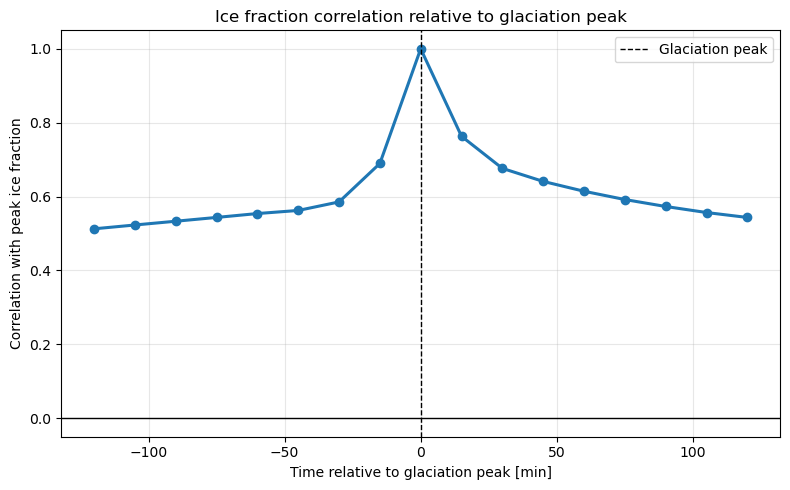

In [94]:
plt.figure(figsize=(8, 5))

plt.plot(
    corr_peak_df["rel_time_min"],
    corr_peak_df["corr_with_peak"],
    marker="o",
    linewidth=2.2,
)

plt.axvline(0, color="k", linewidth=1, linestyle="--", label="Glaciation peak")
plt.axhline(0, color="k", linewidth=1)

plt.xlabel("Time relative to glaciation peak [min]")
plt.ylabel("Correlation with peak ice fraction")
plt.title("Ice fraction correlation relative to glaciation peak")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
cloud_df.keys()

Index(['tracknumber', 'is_large_pix_cloud', 'is_cot_valid_cloud',
       'is_ctp_valid_cloud', 'is_liq', 'is_mix', 'is_ice', 'max_water_frac',
       'max_ice_fraction', 'avg_size[km]', 'max_size[km]', 'min_size[km]',
       'avg_size[px]', 'max_size[px]', 'min_size[px]', 'track_start_time',
       'track_length', 'avg_cot', 'avg_ctp', 'avg_ctt',
       'glaciation_start_time', 'glaciation_end_time', 'avg_lat', 'avg_lon',
       'start_ice_fraction', 'end_ice_fraction', 'ice_frac_hist', 'cot_hist',
       'cot_std_hist', 'cot_nan_frac_hist', 'ctp_hist', 'ctp_std_hist',
       'ctp_nan_frac_hist', 'ctt_hist', 'ctt_std_hist', 'lat_hist', 'lon_hist',
       'size_hist_km', 'min_temp', 'max_temp', 'pole', 'Hemisphere',
       'Lifetime [h]', 'Radius [km]', 'track_end_time', 'Level',
       'Optical Thickness', 'Cloud type', 'Season'],
      dtype='str')

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# All history columns
hist_cols = [c for c in cloud_df.columns if c.endswith("_hist")]
hist_cols

['ice_frac_hist',
 'cot_hist',
 'cot_std_hist',
 'cot_nan_frac_hist',
 'ctp_hist',
 'ctp_std_hist',
 'ctp_nan_frac_hist',
 'ctt_hist',
 'ctt_std_hist',
 'lat_hist',
 'lon_hist']

In [14]:
from tqdm.auto import tqdm

In [68]:
def pooled_autocorr_hist_column(series, max_lag=20, min_len=4, demean=True):
    """
    Compute pooled lag autocorrelation for one *_hist column.

    Parameters
    ----------
    series : pd.Series
        Each element is list/array time series.
    max_lag : int
        Maximum lag in time steps.
    min_len : int
        Minimum valid length of a cloud time series.
    demean : bool
        If True, subtract each cloud's own mean before pooling.
        Usually recommended for cloud histories.

    Returns
    -------
    pd.DataFrame with columns:
        lag, autocorr, n_pairs
    """
    sum_xx = np.zeros(max_lag + 1, dtype=float)
    sum_x2 = np.zeros(max_lag + 1, dtype=float)
    n_pairs = np.zeros(max_lag + 1, dtype=int)
    arrs = series.dropna().to_numpy()
    eps=1e-4
    for arr in tqdm(arrs, desc=f"Autocorr {series.name}", total=len(arrs)):
        x = np.asarray(arr, dtype=float)

        # Remove non-finite values
        valid = np.isfinite(x) & (x>=0-eps) & (x<=1+eps)
        x[~valid]==np.nan

        if valid.sum() < min_len:
            continue
        if x.max()<=0+eps:
            continue
        if demean:
            mean_x = np.nanmean(x[valid])
            x = x - mean_x

        for lag in range(max_lag + 1):
            if len(x) <= lag:
                continue

            x0 = x[:-lag] if lag > 0 else x
            x1 = x[lag:] if lag > 0 else x

            mask = np.isfinite(x0) & np.isfinite(x1) #& (x0>=0-eps) & (x0<=1+eps) & (x1>=0-eps) & (x1<=1+eps))

            if mask.sum() == 0:
                continue

            x0 = x0[mask]
            x1 = x1[mask]

            sum_xx[lag] += np.sum(x0 * x1)
            sum_x2[lag] += np.sum(x0 * x0)
            n_pairs[lag] += len(x0)

    autocorr = sum_xx / sum_x2
    autocorr[sum_x2 == 0] = np.nan

    return pd.DataFrame({
        "lag": np.arange(max_lag + 1),
        "autocorr": autocorr,
        "n_pairs": n_pairs,
    })

In [58]:
max_lag = 10  # 20 * 15 min = 5 hours if cadence is 15 min

autocorr_results = {}
hist_cols=["ice_frac_hist","cot_hist"]
for col in hist_cols:
    print(f"Computing autocorrelation for {col}")
    autocorr_results[col] = pooled_autocorr_hist_column(
        sample[col],
        max_lag=max_lag,
        min_len=4,
        demean=True,
    )

Computing autocorrelation for ice_frac_hist


Autocorr ice_frac_hist: 100%|██████████| 50000/50000 [00:02<00:00, 23929.70it/s]


Computing autocorrelation for cot_hist


Autocorr cot_hist: 100%|██████████| 50000/50000 [00:00<00:00, 155594.00it/s]


In [48]:
autocorr_results["ice_frac_hist"]

,lag,autocorr,n_pairs
0,0,1.000000,21750
1,1,0.848736,11601
2,2,0.784821,8750
3,3,0.719938,6823
4,4,0.666388,5479
5,5,0.629604,4569
6,6,0.611320,3923
7,7,0.585535,3467
8,8,0.570523,3089
9,9,0.554587,2808


In [42]:
autocorr_df = pd.concat(
    [
        df.assign(variable=col)
        for col, df in autocorr_results.items()
    ],
    ignore_index=True
)

autocorr_df["lag_min"] = autocorr_df["lag"] * 15
autocorr_df.head()

ValueError: No objects to concatenate

In [69]:
def bootstrap_autocorr(
    series,
    max_lag=8,
    min_len=4,
    demean=True,
    n_boot=10,
    random_state=0,
):
    rng = np.random.default_rng(random_state)

    arrs = series.dropna().to_numpy()
    n = len(arrs)

    boot_corrs = np.full((n_boot, max_lag + 1), np.nan)

    for b in range(n_boot):
        inds = rng.integers(0, n, size=n)
        sampled_series = pd.Series(arrs[inds])

        df_b = pooled_autocorr_hist_column(
            sampled_series,
            max_lag=max_lag,
            min_len=min_len,
            demean=demean,
        )

        boot_corrs[b, :] = df_b["autocorr"].to_numpy()

    ci_low = np.nanpercentile(boot_corrs, 2.5, axis=0)
    ci_high = np.nanpercentile(boot_corrs, 97.5, axis=0)

    return pd.DataFrame({
        "lag": np.arange(max_lag + 1),
        "ci_low": ci_low,
        "ci_high": ci_high,
    })

0           True
1           True
2           True
3           True
4           True
           ...  
3932864    False
3932865    False
3932866    False
3932867    False
3932868    False
Name: track_length, Length: 3932869, dtype: bool

In [79]:
sample = cloud_df[cloud_df.track_length>=pd.Timedelta(hours=1)].sample(10000,random_state=1)

In [80]:
main = pooled_autocorr_hist_column(
    sample["ice_frac_hist"],
    max_lag=8,
    min_len=4,
    demean=True,
)

ci = bootstrap_autocorr(
    sample["ice_frac_hist"],
    max_lag=8,
    min_len=4,
    demean=True,
    n_boot=20,
)

out = main.merge(ci, on="lag")
out["lag_min"] = out["lag"] * 15

out["statistically_significant"] = (
    (out["ci_low"] > 0) | (out["ci_high"] < 0)
)

out["practically_significant"] = (
    np.abs(out["autocorr"]) >= 0.1
)

out["significant_and_meaningful"] = (
    out["statistically_significant"]
    & out["practically_significant"]
)

out

Autocorr None: 100%|██████████| 10000/10000 [00:00<00:00, 23088.14it/s]


,lag,autocorr,n_pairs,ci_low,ci_high,lag_min,statistically_significant,practically_significant,significant_and_meaningful
0,0,1.000000,75236,1.000000,1.000000,0,True,True,True
1,1,0.624005,68910,0.601735,0.646347,15,True,True,True
2,2,0.350713,62584,0.316762,0.388642,30,True,True,True
3,3,0.159102,56258,0.131224,0.212140,45,True,True,True
4,4,0.040477,49932,0.003999,0.098821,60,True,False,False
5,5,-0.014940,43606,-0.062647,0.048712,75,False,False,False
6,6,-0.072690,38776,-0.123950,-0.000225,90,True,False,False
7,7,-0.110329,34919,-0.166114,-0.028306,105,True,True,True
8,8,-0.145062,31734,-0.190977,-0.055351,120,True,True,True


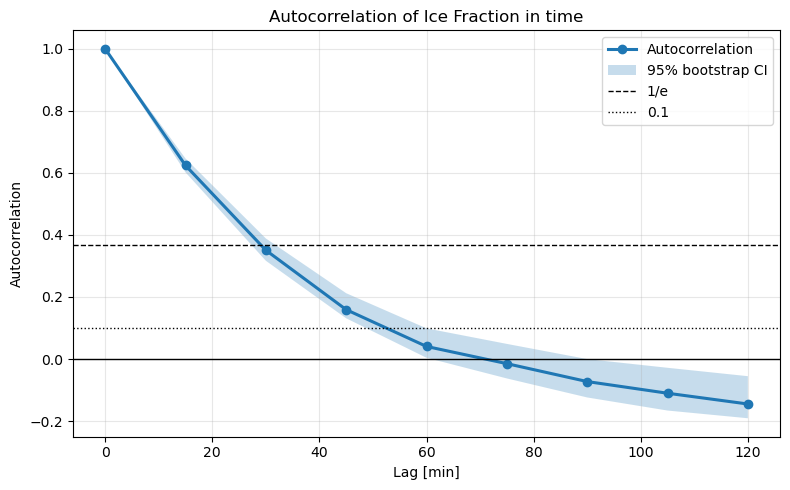

In [122]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 5))

plt.plot(
    out["lag_min"],
    out["autocorr"],
    marker="o",
    linewidth=2.2,
    label="Autocorrelation",
)

plt.fill_between(
    out["lag_min"],
    out["ci_low"],
    out["ci_high"],
    alpha=0.25,
    label="95% bootstrap CI",
)

plt.axhline(0, color="k", linewidth=1)
plt.axhline(1 / np.e, color="k", linestyle="--", linewidth=1, label="1/e")
plt.axhline(0.1, color="k", linestyle="dotted", linewidth=1, label="0.1")


plt.xlabel("Lag [min]")
plt.ylabel("Autocorrelation")
plt.title("Autocorrelation of Ice Fraction in time")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

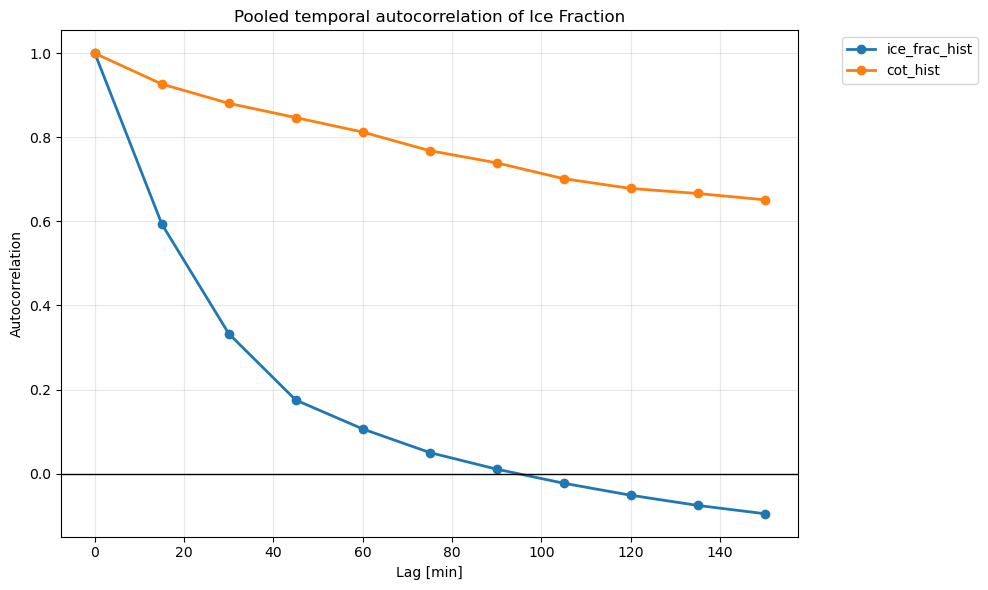

In [60]:
plt.figure(figsize=(10, 6))

for col in hist_cols:
    df = autocorr_results[col]
    plt.plot(
        df["lag"] * 15,
        df["autocorr"],
        marker="o",
        linewidth=2,
        label=col,
    )

plt.axhline(0, color="k", linewidth=1)
plt.xlabel("Lag [min]")
plt.ylabel("Autocorrelation")
plt.title("Pooled temporal autocorrelation of Ice Fraction")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
cloud_df.ctt_hist

0          [270.0298, 269.89166, 269.77982, 269.63846, 26...
1          [270.94476, 271.08136, 271.08093, 271.16843, 2...
2          [269.33667, 269.23175, 269.293, 269.26968, 269...
3          [269.44437, 269.50058, 269.29355, 269.3455, 26...
4          [270.94485, 270.9535, 271.07523, 271.02597, 27...
                                 ...                        
3932864         [240.46983, 240.03049, 240.99542, 240.29419]
3932865          [239.63113, 240.38504, 240.7577, 240.23364]
3932866         [239.72002, 239.78299, 240.07066, 240.42955]
3932867           [240.43048, 240.8755, 239.60854, 239.8227]
3932868           [238.43791, 239.618, 239.72766, 240.09604]
Name: ctt_hist, Length: 3932869, dtype: object